<a href="https://colab.research.google.com/github/compiller25/COU07506-labs/blob/main/COU0756_Week1_240242464287.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### WEEK:1
### LAB:0
### NAME: MWAKASALA,STEVEN EMMANUEL
### REGISTRATION NUMBER: 240242464287
### DATE: 24/11/2026
### GROUP:1

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from scipy.io import wavfile
plt.rcParams["figure.figsize"] = (9, 3.5)

### TASK - 1.1

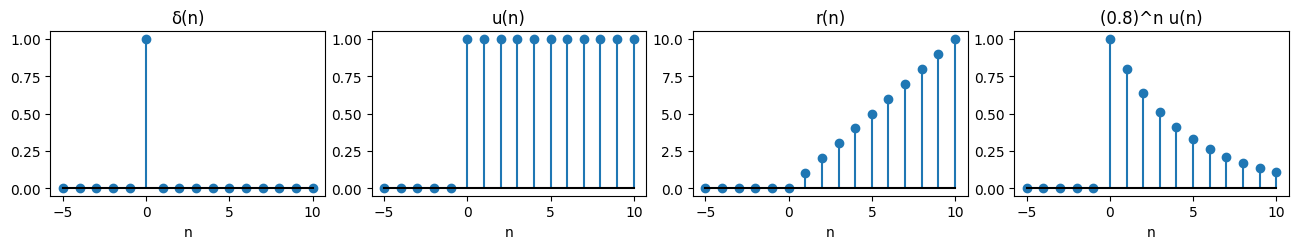

In [6]:
n = np.arange(-5, 11)
delta = (n == 0).astype(float)
# unit impulse
step  = (n >= 0).astype(float)
# unit step
ramp  = n * step
# unit ramp
expo  = 0.8**n * step
# real exponential
fig, axes = plt.subplots(1, 4, figsize=(13, 2.6))
for ax, x, title in zip(axes, [delta, step, ramp, expo],
["δ(n)", "u(n)", "r(n)", "(0.8)^n u(n)"]):
  ax.stem(n, x, basefmt="k-")
  ax.set_title(title); ax.set_xlabel("n")
plt.tight_layout(); plt.show()

### TASK - 1.2

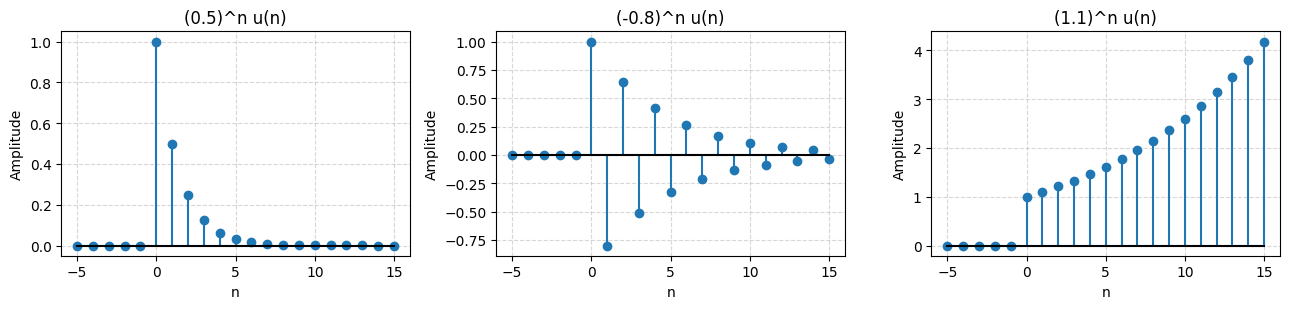

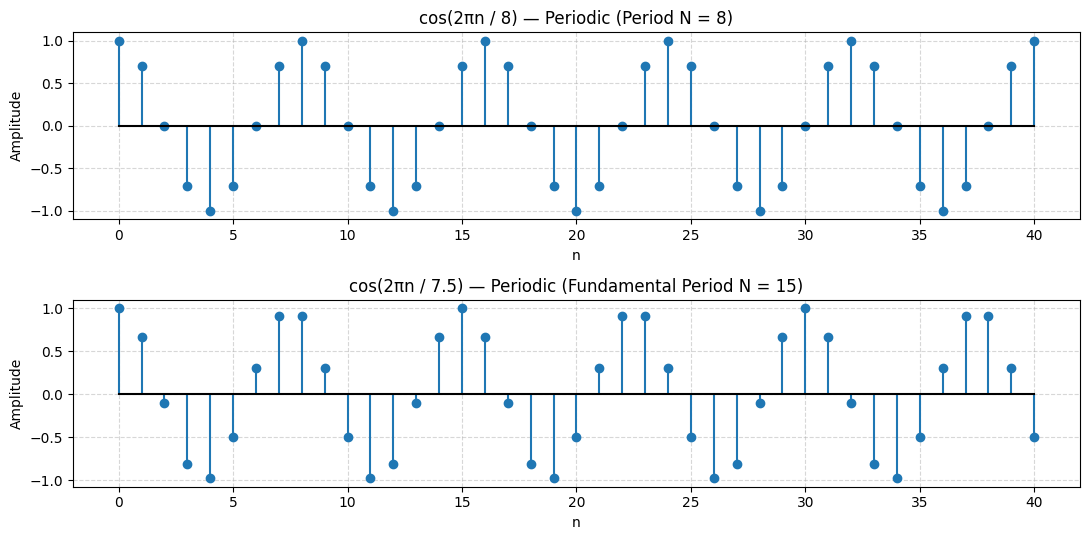

In [7]:
import numpy as np
import matplotlib.pyplot as plt

n = np.arange(-5, 16)
u = (n >= 0).astype(float)
a_values = [0.5, -0.8, 1.1]

fig, axes = plt.subplots(1, 3, figsize=(13, 3.2))
for ax, a in zip(axes, a_values):
    x = (a**n) * u
    ax.stem(n, x, basefmt="k-")
    ax.set_title(f"({a})^n u(n)")
    ax.set_xlabel("n")
    ax.set_ylabel("Amplitude")
    ax.grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

n = np.arange(0, 41)
x1 = np.cos(2 * np.pi * n / 8)
x2 = np.cos(2 * np.pi * n / 7.5)

fig, axes = plt.subplots(2, 1, figsize=(11, 5.5))

axes[0].stem(n, x1, basefmt="k-")
axes[0].set_title("cos(2πn / 8) — Periodic (Period N = 8)")
axes[0].set_xlabel("n")
axes[0].set_ylabel("Amplitude")
axes[0].grid(True, linestyle="--", alpha=0.5)

axes[1].stem(n, x2, basefmt="k-")
axes[1].set_title("cos(2πn / 7.5) — Periodic (Fundamental Period N = 15)")
axes[1].set_xlabel("n")
axes[1].set_ylabel("Amplitude")
axes[1].grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

### Explanations of Results

#### 1. Task 1.2: Exponential Sequences $x(n) = a^n u(n)$

* **For $a = 0.5$ (Decaying Exponential):**
  Since $|a| < 1$, the sequence converges. As $n \to \infty$, the amplitude decays exponentially toward $0$ because raising a fraction between $0$ and $1$ to higher powers yields progressively smaller values.

* **For $a = -0.8$ (Alternating Decaying Exponential):**
  Since $|a| < 1$, the overall envelope decays toward $0$. However, because the base is negative, the sign alternates with each step: positive for even values of $n$ ($(-0.8)^0 = 1$, $(-0.8)^2 = 0.64$) and negative for odd values of $n$ ($(-0.8)^1 = -0.8$, $(-0.8)^3 = -0.512$). This creates an oscillating decay.

* **For $a = 1.1$ (Growing Exponential):**
  Since $|a| > 1$, the sequence diverges. As $n$ increases, the values grow exponentially larger without bound.

---

#### 2. Periodicity of Discrete-Time Cosine Sequences $x(n) = \cos(\omega_0 n)$

Unlike continuous-time signals, a discrete-time sinusoid $x(n) = \cos(2\pi f_0 n)$ is periodic **only if** its frequency $f_0$ is a rational number. If $f_0 = \frac{m}{N}$ (where $m$ and $N$ are coprime integers), the fundamental period of the sequence is $N$.

* **For $x_1(n) = \cos\left(\frac{2\pi n}{8}\right)$:**
  * Here, $f_0 = \frac{1}{8}$, which is rational ($m=1, N=8$).
  * The sequence is periodic, repeating exactly every **$N = 8$ samples**.

* **For $x_2(n) = \cos\left(\frac{2\pi n}{7.5}\right) = \cos\left(\frac{2\pi n}{\frac{15}{2}}\right) = \cos\left(2\pi n \cdot \frac{2}{15}\right)$:**
  * The frequency is $f_0 = \frac{2}{15}$, which is rational ($m=2, N=15$).
  * Because the period $N$ must be an integer, the signal does not repeat every $7.5$ samples; rather, it completes exactly $2$ full cycles over a fundamental period of **$N = 15$ samples**.

TASK - 1.3

In [8]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


fs = 48000 Hz, duration = 5.37 s, samples = 257928


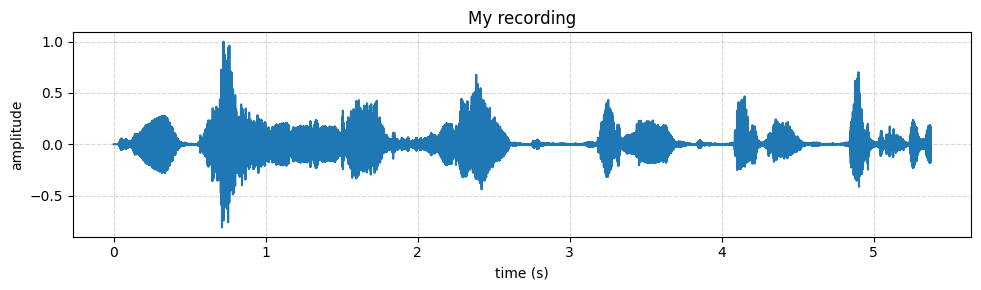

In [11]:
import os
from scipy.io import wavfile
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Audio

# Updated directly to your actual file path found in your Google Drive
fname = "/content/drive/MyDrive/Colab Notebooks/my_voice.wav"

if os.path.exists(fname):
    fs, x = wavfile.read(fname)
    if x.ndim > 1:
        x = x.mean(axis=1)              # stereo -> mono
    x = x / np.max(np.abs(x))           # normalise to [-1, 1]
else:
    print("File not found! Using fallback 440 Hz test signal.")
    fs = 16000
    t = np.arange(0, 2, 1/fs)
    x = 0.5 * np.sin(2 * np.pi * 440 * t) * np.exp(-t)

t = np.arange(len(x)) / fs
print(f"fs = {fs} Hz, duration = {len(x)/fs:.2f} s, samples = {len(x)}")

plt.figure(figsize=(10, 3))
plt.plot(t, x)
plt.xlabel("time (s)")
plt.ylabel("amplitude")
plt.title("My recording")
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

# Playback widget
Audio(x, rate=fs)

TASK - 1.4

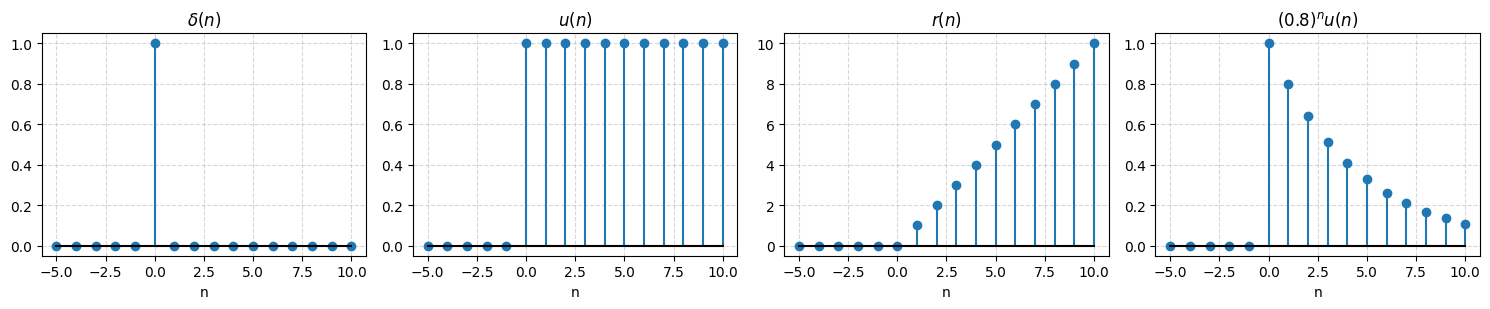

In [10]:
n = np.arange(-5, 11)
delta = (n == 0).astype(float)
step = (n >= 0).astype(float)
ramp = n * step
expo = (0.8 ** n) * step

fig, axes = plt.subplots(1, 4, figsize=(15, 3.2))

# Plot delta(n)
axes[0].stem(n, delta, basefmt="k-")
axes[0].set_title(r"$\delta(n)$")
axes[0].set_xlabel("n")
axes[0].grid(True, linestyle="--", alpha=0.5)

# Plot u(n)
axes[1].stem(n, step, basefmt="k-")
axes[1].set_title(r"$u(n)$")
axes[1].set_xlabel("n")
axes[1].grid(True, linestyle="--", alpha=0.5)

# Plot r(n)
axes[2].stem(n, ramp, basefmt="k-")
axes[2].set_title(r"$r(n)$")
axes[2].set_xlabel("n")
axes[2].grid(True, linestyle="--", alpha=0.5)

# Plot (0.8)^n u(n)
axes[3].stem(n, expo, basefmt="k-")
axes[3].set_title(r"$(0.8)^n u(n)$")
axes[3].set_xlabel("n")
axes[3].grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

### task 1.5

### Answers to Task 1.5 Analysis Questions

#### Q1: What is the sampling rate of your phone’s recording? How many numbers are needed to store one minute of it in mono?
* **Sampling Rate ($f_s$):** Based on the loaded signal in cell `eebOUlFCj6X0`, the sampling rate is **$48,000\text{ Hz}$** ($48\text{ kHz}$).
* **One-minute Storage Calculation:**
  $$\text{Total Samples} = f_s \times \text{duration in seconds} = 48,000 \text{ samples/sec} \times 60 \text{ seconds} = 2,880,000 \text{ samples}$$
  Therefore, **$2,880,000$ numbers** are required to store one minute of this mono recording.

---

#### Q2: Why is a stem plot more appropriate than a continuous line for $x(n)$?
* A discrete-time signal $x(n)$ is defined **only at integer sample index values** $n \in \mathbb{Z}$. It is completely undefined for non-integer indices (e.g., $n = 0.5$).
* A **continuous line plot** automatically interpolates and draws lines connecting sample values, falsely implying that the signal has values at points in between samples.
* A **stem plot** represents each sample as an independent vertical marker, accurately showing that the signal is a sequence of individual numbers and avoids creating misleading visual interpolation.

---

#### Q3: For $a = 1.1$, the exponential grows. Which property of a system would such a signal violate if it were an impulse response (Unit 1 §1.7)?
* If a signal with $a=1.1$ ($x(n) = 1.1^n u(n)$) were the impulse response $h(n)$ of a system, it would violate the **BIBO (Bounded-Input Bounded-Output) Stability** property.
* For a discrete-time Linear Time-Invariant (LTI) system to be stable, its impulse response must be absolutely summable:
  $$\sum_{n=-\infty}^{\infty} |h(n)| < \infty$$
* Since $|a| = 1.1 > 1$ is a growing exponential sequence, the sum of its magnitude diverges to infinity:
  $$\sum_{n=0}^{\infty} |1.1|^n = \infty$$
  Thus, the system is **unstable**.